# 01. DATA UNDERSTANDING & DATA QUALITY

**Data Understanding — Tìm hiểu dữ liệu**
- Khám phá cấu trúc và kích thước của các bảng dữ liệu.
- Xác định ý nghĩa, kiểu dữ liệu của các trường.
- Tìm hiểu mối quan hệ giữa các bảng và các khóa dùng để liên kết dữ liệu.

**Data Quality — Đánh giá chất lượng dữ liệu**
- Kiểm tra các giá trị bị thiếu (Missing Data).
- Phát hiện các giá trị bất thường (Outliers).
- Phân tích sự phân bố của biến kết quả `final_result` để đánh giá tình trạng mất cân bằng dữ liệu (Data Imbalance).
- Đề xuất phương án xử lý phù hợp trước khi sử dụng dữ liệu cho Machine Learning.

Sau khi hoàn thành notebook, có thể hiểu được cấu trúc và ý nghĩa của bộ dữ liệu OULAD, xác định các vấn đề về chất lượng dữ liệu và đưa ra phương án xử lý phù hợp. Những kết quả này sẽ làm cơ sở cho bước phân tích khám phá dữ liệu (EDA), xây dựng đặc trưng và tiền xử lý dữ liệu ở các notebook tiếp theo.

### **1. Import libraries and load data.**

In [51]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# File path management
from pathlib import Path

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [52]:
from pathlib import Path
DATA_DIR = Path("raw_data")

csv_files = sorted(DATA_DIR.glob("*.csv"))

print("Number of CSV files found:", len(csv_files))
print("\nList of CSV files:")

for csv_file in csv_files:
    print("-", csv_file.name)


Number of CSV files found: 7

List of CSV files:
- assessments.csv
- courses.csv
- studentAssessment.csv
- studentInfo.csv
- studentRegistration.csv
- studentVle.csv
- vle.csv


=> The dataset directory contains 7 CSV files, each storing a distinct set of information regarding online learning activities. Each table will be exxplored individually to determine its structure, schema, and inter-table relationships.

### **2. Dataset overview.**

In [53]:
data = {}

for file in csv_files:
    table_name = file.stem
    data[table_name] = pd.read_csv(file)

    print(f"Loaded: {table_name} with shape {data[table_name].shape}")


Loaded: assessments with shape (206, 6)
Loaded: courses with shape (22, 3)
Loaded: studentAssessment with shape (173912, 5)
Loaded: studentInfo with shape (32593, 12)
Loaded: studentRegistration with shape (32593, 5)
Loaded: studentVle with shape (10655280, 6)
Loaded: vle with shape (6364, 6)


=> There is a noticeable difference in the number of records across the tables:

- The `studentVLE` table contains 10,655,280 rows - largest table.
- Meanwhile, the `courses` table contains of only 22 rows.

**This difference demonstrates that the tables operate at differet levels of granularity.**

In [54]:
for table_name, df in data.items():
    print(f"\n===== {table_name} =====")
    print(df.dtypes)


===== assessments =====
code_module              str
code_presentation        str
id_assessment          int64
assessment_type          str
date                 float64
weight               float64
dtype: object

===== courses =====
code_module                     str
code_presentation               str
module_presentation_length    int64
dtype: object

===== studentAssessment =====
id_assessment       int64
id_student          int64
date_submitted      int64
is_banked           int64
score             float64
dtype: object

===== studentInfo =====
code_module               str
code_presentation         str
id_student              int64
gender                    str
region                    str
highest_education         str
imd_band                  str
age_band                  str
num_of_prev_attempts    int64
studied_credits         int64
disability                str
final_result              str
dtype: object

===== studentRegistration =====
code_module                str
code_p

In [55]:
for table_name, df in data.items():
    print(f"\n===== {table_name} =====")
    print(df.columns.tolist())


===== assessments =====
['code_module', 'code_presentation', 'id_assessment', 'assessment_type', 'date', 'weight']

===== courses =====
['code_module', 'code_presentation', 'module_presentation_length']

===== studentAssessment =====
['id_assessment', 'id_student', 'date_submitted', 'is_banked', 'score']

===== studentInfo =====
['code_module', 'code_presentation', 'id_student', 'gender', 'region', 'highest_education', 'imd_band', 'age_band', 'num_of_prev_attempts', 'studied_credits', 'disability', 'final_result']

===== studentRegistration =====
['code_module', 'code_presentation', 'id_student', 'date_registration', 'date_unregistration']

===== studentVle =====
['code_module', 'code_presentation', 'id_student', 'id_site', 'date', 'sum_click']

===== vle =====
['id_site', 'code_module', 'code_presentation', 'activity_type', 'week_from', 'week_to']


In [56]:
# Summarize the structure of all tables
table_summary = []

for table_name, df in data.items():
    table_summary.append({
        "Table": table_name,
        "Rows": df.shape[0],
        "Columns": df.shape[1],
        "Column Names": ", ".join(df.columns)
    })

table_summary = pd.DataFrame(table_summary)

display(table_summary)

,Table,Rows,Columns,Column Names
0,assessments,206,6,"code_module, code_presentation, id_assessment, assessment_type, date, weight"
1,courses,22,3,"code_module, code_presentation, module_presentation_length"
2,studentAssessment,173912,5,"id_assessment, id_student, date_submitted, is_banked, score"
3,studentInfo,32593,12,"code_module, code_presentation, id_student, gender, region, highest_education, imd_band, age_band, num_of_prev_attempts, studied_credits, disability, final_result"
4,studentRegistration,32593,5,"code_module, code_presentation, id_student, date_registration, date_unregistration"
5,studentVle,10655280,6,"code_module, code_presentation, id_student, id_site, date, sum_click"
6,vle,6364,6,"id_site, code_module, code_presentation, activity_type, week_from, week_to"


### **3. Data scheme, relationship.**

In [57]:
for table_name, df in data.items():
    print(f"\n===== {table_name} =====")
    display(pd.DataFrame({
        "Column": df.columns,
        "Data Type": df.dtypes.astype(str).values
    }))


===== assessments =====


,Column,Data Type
0,code_module,str
1,code_presentation,str
2,id_assessment,int64
3,assessment_type,str
4,date,float64
5,weight,float64



===== courses =====


,Column,Data Type
0,code_module,str
1,code_presentation,str
2,module_presentation_length,int64



===== studentAssessment =====


...

,Column,Data Type
0,code_module,str
1,code_presentation,str
2,id_student,int64
3,date_registration,float64
4,date_unregistration,float64



===== studentVle =====


,Column,Data Type
0,code_module,str
1,code_presentation,str
2,id_student,int64
3,id_site,int64
4,date,int64
5,sum_click,int64



===== vle =====


,Column,Data Type
0,id_site,int64
1,code_module,str
2,code_presentation,str
3,activity_type,str
4,week_from,float64
5,week_to,float64


`studentInfo`: Stores students' demographic information, academic characteristics, and final outcomes.

`studentRegistration`: Records course registration details and the unregistration date (withdrawal timestamp) for each student.

`courses`: Contains metadata on available courses (modules) and the duration of each presentation (semester).

`assessments`: Stores information regarding course assessments, including assessment types and their respective weightings.

`studentAssessment`: Records students' assessment scores and submission dates.

`studentVle`: Tracks students' interaction logs (clickstream data) with online learning resources over time.

`vle`: Contains metadata about online learning materials/resources, including activity types and active time frames.

In [58]:
schema_info = {
    "Table": [
        "studentInfo",
        "studentInfo",
        "studentInfo",
        "studentInfo",
        "studentAssessment",
        "studentAssessment",
        "studentVle",
        "studentVle",
        "assessments",
        "assessments",
        "vle",
        "courses"
    ],
    "Column": [
        "gender",
        "age_band",
        "highest_education",
        "final_result",
        "score",
        "id_assessment",
        "sum_click",
        "id_site",
        "assessment_type",
        "weight",
        "activity_type",
        "module_presentation_length"
    ],
    "Meaning": [
        "Giới tính sinh viên",
        "Nhóm tuổi của sinh viên",
        "Trình độ học vấn cao nhất",
        "Kết quả cuối cùng của môn học",
        "Điểm đánh giá của sinh viên",
        "Mã định danh bài đánh giá",
        "Số lượt tương tác với tài nguyên",
        "Mã định danh tài nguyên trực tuyến",
        "Loại bài đánh giá",
        "Trọng số của bài đánh giá",
        "Loại hoạt động trực tuyến",
        "Thời lượng kỳ học tính theo ngày"
    ],
    "Data Type": [
        "Categorical",
        "Categorical",
        "Categorical",
        "Categorical / Target",
        "Numerical",
        "Identifier",
        "Numerical",
        "Identifier",
        "Categorical",
        "Numerical",
        "Categorical",
        "Numerical"
    ]
}

schema_df = pd.DataFrame(schema_info)
display(schema_df)

,Table,Column,Meaning,Data Type
0,studentInfo,gender,Giới tính sinh viên,Categorical
1,studentInfo,age_band,Nhóm tuổi của sinh viên,Categorical
2,studentInfo,highest_education,Trình độ học vấn cao nhất,Categorical
3,studentInfo,final_result,Kết quả cuối cùng của môn học,Categorical / Target
4,studentAssessment,score,Điểm đánh giá của sinh viên,Numerical
5,studentAssessment,id_assessment,Mã định danh bài đánh giá,Identifier
6,studentVle,sum_click,Số lượt tương tác với tài nguyên,Numerical
7,studentVle,id_site,Mã định danh tài nguyên trực tuyến,Identifier
8,assessments,assessment_type,Loại bài đánh giá,Categorical
9,assessments,weight,Trọng số của bài đánh giá,Numerical


- selecting join key.

In [59]:
assessments = data["assessments"]
student_assessment = data["studentAssessment"]

# Find common columns between the two tables
common_columns = sorted(
    set(assessments.columns)
    & set(student_assessment.columns)
)

print("Columns in assessments:")
print(assessments.columns.tolist())

print("\nColumns in studentAssessment:")
print(student_assessment.columns.tolist())

print("\nCommon columns:")
print(common_columns)

Columns in assessments:
['code_module', 'code_presentation', 'id_assessment', 'assessment_type', 'date', 'weight']

Columns in studentAssessment:
['id_assessment', 'id_student', 'date_submitted', 'is_banked', 'score']

Common columns:
['id_assessment']


In [60]:
print("Sample from assessments:")
display(
    assessments[["id_assessment", "assessment_type"]].head(10)
)

print("Sample from studentAssessment:")
display(
    student_assessment[
        ["id_assessment", "id_student", "score"]
    ].head(10)
)

Sample from assessments:


,id_assessment,assessment_type
0,1752,TMA
1,1753,TMA
2,1754,TMA
3,1755,TMA
4,1756,TMA
5,1757,Exam
6,1758,TMA
7,1759,TMA
8,1760,TMA
9,1761,TMA


Sample from studentAssessment:


,id_assessment,id_student,score
0,1752,11391,78.0
1,1752,28400,70.0
2,1752,31604,72.0
3,1752,32885,69.0
4,1752,38053,79.0
5,1752,45462,70.0
6,1752,45642,72.0
7,1752,52130,72.0
8,1752,53025,71.0
9,1752,57506,68.0


In [61]:
print(
    "Number of rows in assessments:",
    len(assessments)
)

print(
    "Number of unique id_assessment:",
    assessments["id_assessment"].nunique()
)

print(
    "Number of duplicated id_assessment:",
    assessments["id_assessment"].duplicated().sum()
)

Number of rows in assessments: 206
Number of unique id_assessment: 206
Number of duplicated id_assessment: 0


In [62]:
assessment_ids = set(assessments["id_assessment"].dropna())
student_assessment_ids = set(
    student_assessment["id_assessment"].dropna()
)

print(
    "Unique IDs in assessments:",
    len(assessment_ids)
)

print(
    "Unique IDs in studentAssessment:",
    len(student_assessment_ids)
)

print(
    "IDs in studentAssessment not found in assessments:",
    len(student_assessment_ids - assessment_ids)
)

print(
    "IDs in assessments not found in studentAssessment:",
    len(assessment_ids - student_assessment_ids)
)

Unique IDs in assessments: 206
Unique IDs in studentAssessment: 188
IDs in studentAssessment not found in assessments: 0
IDs in assessments not found in studentAssessment: 18


In [63]:
# Relationship 2: studentVle - vle

student_vle = data["studentVle"]
vle = data["vle"]

# 1. Find common columns
common_columns = sorted(
    set(student_vle.columns) & set(vle.columns)
)

print("1. Common columns:", common_columns)

# 2. Inspect sample records
print("\n2. Sample from studentVle:")
display(student_vle[common_columns].head())

print("Sample from vle:")
display(vle[common_columns].head())

# 3. Check uniqueness of candidate keys in vle
for keys in [["id_site"], ["id_site", "code_module", "code_presentation"]]:
    print(f"\n3. Candidate key: {keys}")
    print("Duplicate combinations:",
          vle.duplicated(subset=keys).sum())
    print("Missing key values:",
          vle[keys].isna().any(axis=1).sum())

# 4. Check whether studentVle references valid resources
keys = ["id_site", "code_module", "code_presentation"]

vle_keys = vle[keys].drop_duplicates()
student_vle_keys = student_vle[keys].drop_duplicates()

check = student_vle_keys.merge(
    vle_keys,
    on=keys,
    how="left",
    indicator=True
)

print("\n4. Unique key combinations in studentVle:",
      len(student_vle_keys))
print("Unmatched combinations:",
      (check["_merge"] == "left_only").sum())
print("Matched combinations:",
      (check["_merge"] == "both").sum())

1. Common columns: ['code_module', 'code_presentation', 'id_site']

2. Sample from studentVle:


,code_module,code_presentation,id_site
0,AAA,2013J,546652
1,AAA,2013J,546652
2,AAA,2013J,546652
3,AAA,2013J,546614
4,AAA,2013J,546714


Sample from vle:


,code_module,code_presentation,id_site
0,AAA,2013J,546943
1,AAA,2013J,546712
2,AAA,2013J,546998
3,AAA,2013J,546888
4,AAA,2013J,547035



3. Candidate key: ['id_site']
Duplicate combinations: 0
Missing key values: 0

3. Candidate key: ['id_site', 'code_module', 'code_presentation']
Duplicate combinations: 0
Missing key values: 0

4. Unique key combinations in studentVle: 6268
Unmatched combinations: 0
Matched combinations: 6268


In [64]:
# Relationship 3: studentInfo - studentRegistration

student_info = data["studentInfo"]
student_registration = data["studentRegistration"]

# 1. Find common columns
common_columns = sorted(
    set(student_info.columns)
    & set(student_registration.columns)
)

print("1. Common columns:", common_columns)

# 2. Inspect sample records
print("\n2. Sample from studentInfo:")
display(student_info[common_columns].head())

print("Sample from studentRegistration:")
display(student_registration[common_columns].head())

# 3. Test candidate keys
candidate_keys = [
    ["id_student"],
    ["id_student", "code_module", "code_presentation"]
]

for keys in candidate_keys:
    print(f"\n3. Candidate key: {keys}")

    print(
        "Duplicates in studentInfo:",
        student_info.duplicated(subset=keys).sum()
    )

    print(
        "Duplicates in studentRegistration:",
        student_registration.duplicated(subset=keys).sum()
    )

    print(
        "Missing key values in studentInfo:",
        student_info[keys].isna().any(axis=1).sum()
    )

    print(
        "Missing key values in studentRegistration:",
        student_registration[keys].isna().any(axis=1).sum()
    )

# 4. Check whether records match using the composite key
keys = ["id_student", "code_module", "code_presentation"]

info_keys = student_info[keys].drop_duplicates()
registration_keys = student_registration[keys].drop_duplicates()

match_check = info_keys.merge(
    registration_keys,
    on=keys,
    how="left",
    indicator=True
)

reverse_check = registration_keys.merge(
    info_keys,
    on=keys,
    how="left",
    indicator=True
)

print("\n4. Matching results using composite key:")
print(
    "Records in studentInfo without registration:",
    (match_check["_merge"] == "left_only").sum()
)
print(
    "Records in studentRegistration without studentInfo:",
    (reverse_check["_merge"] == "left_only").sum()
)

1. Common columns: ['code_module', 'code_presentation', 'id_student']

2. Sample from studentInfo:


,code_module,code_presentation,id_student
0,AAA,2013J,11391
1,AAA,2013J,28400
2,AAA,2013J,30268
3,AAA,2013J,31604
4,AAA,2013J,32885


Sample from studentRegistration:


,code_module,code_presentation,id_student
0,AAA,2013J,11391
1,AAA,2013J,28400
2,AAA,2013J,30268
3,AAA,2013J,31604
4,AAA,2013J,32885



3. Candidate key: ['id_student']
Duplicates in studentInfo: 3808
Duplicates in studentRegistration: 3808
Missing key values in studentInfo: 0
Missing key values in studentRegistration: 0

3. Candidate key: ['id_student', 'code_module', 'code_presentation']
Duplicates in studentInfo: 0
Duplicates in studentRegistration: 0
Missing key values in studentInfo: 0
Missing key values in studentRegistration: 0

4. Matching results using composite key:
Records in studentInfo without registration: 0
Records in studentRegistration without studentInfo: 0


In [65]:
# 3.2. Check table relationships

relationships = [
    ("assessments", "studentAssessment", ["id_assessment"]),
    ("studentVle", "vle", ["id_site"]),
    (
        "studentInfo",
        "studentRegistration",
        ["id_student", "code_module", "code_presentation"]
    ),
    (
        "courses",
        "assessments",
        ["code_module", "code_presentation"]
    ),
    (
        "courses",
        "studentInfo",
        ["code_module", "code_presentation"]
    )
]

for table1, table2, keys in relationships:
    valid = all(
        key in data[table1].columns
        and key in data[table2].columns
        for key in keys
    )

    print(
        f"{table1} <-> {table2} | "
        f"Keys: {keys} | Valid: {valid}"
    )

assessments <-> studentAssessment | Keys: ['id_assessment'] | Valid: True
studentVle <-> vle | Keys: ['id_site'] | Valid: True
studentInfo <-> studentRegistration | Keys: ['id_student', 'code_module', 'code_presentation'] | Valid: True
courses <-> assessments | Keys: ['code_module', 'code_presentation'] | Valid: True
courses <-> studentInfo | Keys: ['code_module', 'code_presentation'] | Valid: True


=> Table Relationships:

- assessments and studentAssessment: The id_assessment field links assessment information to students' assessment records.

- studentVle and vle: The id_site field links students' online activity records to information about learning resources.

- studentInfo and studentRegistration: The fields id_student, code_module, and code_presentation identify a student within a specific module and presentation.

- courses and assessments: The fields code_module and code_presentation connect course information with its assessments.

- courses and studentInfo: The fields code_module and code_presentation connect course information with student records.


### **4. Data quality analysis.**

- Missing data
- Duplicate data
- Outlier Analysis
- Class Distribution

In [66]:

# 4.1. Missing Data Analysis

missing_summary = []

for table_name, df in data.items():
    for column in df.columns:
        missing_count = df[column].isna().sum()
        missing_percentage = df[column].isna().mean() * 100

        missing_summary.append({
            "Table": table_name,
            "Column": column,
            "Missing_Count": missing_count,
            "Missing_Percentage": round(missing_percentage, 2)
        })

missing_df = pd.DataFrame(missing_summary)

# Sort columns by missing percentage
missing_df = missing_df.sort_values(
    by="Missing_Percentage",
    ascending=False
).reset_index(drop=True)

print("Total columns checked:", len(missing_df))
print("Columns with missing values:",
      (missing_df["Missing_Count"] > 0).sum())

# Display only columns containing missing values
display(
    missing_df[missing_df["Missing_Count"] > 0]
    .reset_index(drop=True)
)


Total columns checked: 43
Columns with missing values: 7


,Table,Column,Missing_Count,Missing_Percentage
0,vle,week_from,5243,82.39
1,vle,week_to,5243,82.39
2,studentRegistration,date_unregistration,22521,69.10
3,assessments,date,11,5.34
4,studentInfo,imd_band,1111,3.41
5,studentRegistration,date_registration,45,0.14
6,studentAssessment,score,173,0.10




The missing data analysis examined 43 columns across the seven OULAD tables and identified seven columns containing missing values.

The highest missing-value percentages occur in `week_from` and `week_to` in the `vle` table, both at 82.39%. These missing values indicate that the start and end weeks are not recorded for many learning resources.

The `date_unregistration` column in `studentRegistration` has 22,521 missing values (69.10%). These values may indicate that students did not withdraw from their courses, so they should not automatically be treated as errors.

The `date` column in `assessments` contains 11 missing values (5.34%), while `imd_band` in `studentInfo` has 1,111 missing values (3.41%). In addition, `date_registration` and `score` have relatively low missing-value percentages of 0.14% and 0.10%, respectively.

Overall, the dataset contains missing values in both descriptive attributes and student-related records. These values should be investigated according to their meaning before preprocessing. In particular, meaningful missing values should be distinguished from incomplete or invalid records to avoid losing useful information.

In [67]:

# 4.2. Duplicate Data Analysis

duplicate_summary = []

for table_name, df in data.items():
    duplicate_count = df.duplicated().sum()
    duplicate_percentage = duplicate_count / len(df) * 100

    duplicate_summary.append({
        "Table": table_name,
        "Total_Rows": len(df),
        "Duplicate_Rows": int(duplicate_count),
        "Duplicate_Percentage": round(duplicate_percentage, 4)
    })

duplicate_df = pd.DataFrame(duplicate_summary)

duplicate_df = duplicate_df.sort_values(
    by="Duplicate_Rows",
    ascending=False
).reset_index(drop=True)

display(duplicate_df)


,Table,Total_Rows,Duplicate_Rows,Duplicate_Percentage
0,studentVle,10655280,787170,7.3876
1,courses,22,0,0.0000
2,assessments,206,0,0.0000
3,studentAssessment,173912,0,0.0000
4,studentInfo,32593,0,0.0000
5,studentRegistration,32593,0,0.0000
6,vle,6364,0,0.0000


#### Observations

The duplicate data analysis examined all seven tables in the OULAD dataset.

The `studentVle` table contains 787,170 fully duplicated rows out of 10,655,280 records, representing approximately 7.39% of the table. This indicates that a considerable number of records are identical across all columns and require further investigation.

In contrast, the `courses`, `assessments`, `studentAssessment`, `studentInfo`, `studentRegistration`, and `vle` tables contain no fully duplicated rows.

The duplicated records in `studentVle` should not be removed automatically before investigating their characteristics. Further analysis is needed to determine whether they represent redundant records or valid repeated interactions. Any decision to remove duplicates should be made carefully to avoid losing potentially useful information.

Overall, the `studentVle` table requires further attention during data wrangling, while the other six tables show no fully duplicated rows based on the current check.

In [68]:

# Investigate duplicate records in studentVle

student_vle = data["studentVle"]

# Display a sample of duplicated rows
duplicated_rows = student_vle[
    student_vle.duplicated(keep=False)
]

print("Rows involved in full-duplicate groups:",
      len(duplicated_rows))

display(duplicated_rows.head(10))

# Check duplicates using a potential activity key
activity_key = [
    "code_module",
    "code_presentation",
    "id_student",
    "id_site",
    "date"
]

print("\nDuplicate combinations using activity key:")
print(student_vle.duplicated(subset=activity_key).sum())

print("\nSample repeated activity-key combinations:")
repeated_keys = student_vle[
    student_vle.duplicated(subset=activity_key, keep=False)
].sort_values(activity_key)

display(repeated_keys.head(10))


Rows involved in full-duplicate groups: 1429783


,code_module,code_presentation,id_student,id_site,date,sum_click
1,AAA,2013J,28400,546652,-10,1
2,AAA,2013J,28400,546652,-10,1
62,AAA,2013J,45462,546652,-10,1
63,AAA,2013J,45462,546652,-10,1
178,AAA,2013J,77367,546652,-10,4
180,AAA,2013J,77367,546652,-10,4
191,AAA,2013J,94961,546652,-10,2
193,AAA,2013J,94961,546652,-10,2
432,AAA,2013J,248270,546652,-10,4
442,AAA,2013J,248270,546652,-10,4



Duplicate combinations using activity key:
2195960

Sample repeated activity-key combinations:


,code_module,code_presentation,id_student,id_site,date,sum_click
164258,AAA,2013J,11391,546644,222,5
164261,AAA,2013J,11391,546644,222,11
169286,AAA,2013J,11391,546644,231,7
169287,AAA,2013J,11391,546644,231,7
178915,AAA,2013J,11391,546644,245,2
178916,AAA,2013J,11391,546644,245,3
34734,AAA,2013J,11391,546645,18,8
34736,AAA,2013J,11391,546645,18,7
51962,AAA,2013J,11391,546647,37,6
51964,AAA,2013J,11391,546647,37,3


In [69]:

# Investigate repeated activity keys with different sum_click values

student_vle = data["studentVle"]

activity_key = [
    "code_module",
    "code_presentation",
    "id_student",
    "id_site",
    "date"
]

# Count distinct sum_click values for each candidate key
click_variation = (
    student_vle.groupby(activity_key, dropna=False)["sum_click"]
    .nunique()
)

print("Total unique activity-key combinations:", len(click_variation))
print("Combinations with multiple sum_click values:",
      (click_variation > 1).sum())
print("Combinations with a single sum_click value:",
      (click_variation == 1).sum())

print("\nDistribution of number of distinct sum_click values:")
display(click_variation.value_counts().sort_index().head(10))


Total unique activity-key combinations: 8459320
Combinations with multiple sum_click values: 1179074
Combinations with a single sum_click value: 7280246

Distribution of number of distinct sum_click values:


sum_click
1    7280246
2     997867
3     139730
4      35050
5       5880
6        500
7         36
8         11
Name: count, dtype: int64

In [70]:

# 4.3. Outlier Analysis - Descriptive Statistics

numeric_variables = {
    "studentAssessment.score": data["studentAssessment"]["score"],
    "studentVle.sum_click": data["studentVle"]["sum_click"],
    "studentInfo.studied_credits": data["studentInfo"]["studied_credits"],
    "studentInfo.num_of_prev_attempts":
        data["studentInfo"]["num_of_prev_attempts"]
}

for variable_name, series in numeric_variables.items():
    print(f"\n--- {variable_name} ---")
    display(series.describe().to_frame(name="Value"))



--- studentAssessment.score ---


,Value
count,173739.000000
mean,75.799573
std,18.798107
min,0.000000
25%,65.000000
50%,80.000000
75%,90.000000
max,100.000000



--- studentVle.sum_click ---


,Value
count,1.065528e+07
mean,3.716946e+00
std,8.849047e+00
min,1.000000e+00
25%,1.000000e+00
50%,2.000000e+00
75%,3.000000e+00
max,6.977000e+03



--- studentInfo.studied_credits ---


,Value
count,32593.000000
mean,79.758691
std,41.071900
min,30.000000
25%,60.000000
50%,60.000000
75%,120.000000
max,655.000000



--- studentInfo.num_of_prev_attempts ---


,Value
count,32593.000000
mean,0.163225
std,0.479758
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,6.000000


In [71]:

# Outlier detection using the IQR method

outlier_summary = []

for variable_name, series in numeric_variables.items():
    values = series.dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_mask = (values < lower_bound) | (values > upper_bound)
    outlier_count = int(outlier_mask.sum())

    outlier_summary.append({
        "Variable": variable_name,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": outlier_count,
        "Outlier_Percentage": round(
            outlier_count / len(values) * 100, 2
        )
    })

outlier_df = pd.DataFrame(outlier_summary)

display(outlier_df.round(2))


,Variable,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
0,studentAssessment.score,65.0,90.0,25.0,27.5,127.5,3813,2.19
1,studentVle.sum_click,1.0,3.0,2.0,-2.0,6.0,1314646,12.34
2,studentInfo.studied_credits,60.0,120.0,60.0,-30.0,210.0,350,1.07
3,studentInfo.num_of_prev_attempts,0.0,0.0,0.0,0.0,0.0,4172,12.80


#### Observations

The IQR-based outlier analysis identified potential outliers in all four numerical variables.

The `studentVle.sum_click` variable contains 1,314,646 potential outliers (12.34%). This may reflect a right-skewed distribution in which some students interact with learning resources much more frequently than others. These observations should not automatically be removed.

For `studentInfo.num_of_prev_attempts`, 4,172 values (12.80%) were identified as outliers. The first and third quartiles are both zero, resulting in an IQR of zero. Consequently, positive values are flagged by the IQR method even though they may represent valid previous attempts.

The `studentAssessment.score` variable contains 3,813 potential outliers (2.19%), while `studentInfo.studied_credits` contains 350 (1.07%). These observations require further investigation to determine whether they represent valid extreme values or data quality issues.

Overall, IQR is useful for identifying unusual observations, but outlier treatment should consider the meaning and valid range of each variable. No observations should be removed solely because they fall outside the IQR bounds.

In [72]:

# Check assessment score range

scores = data["studentAssessment"]["score"]

print("Minimum score:", scores.min())
print("Maximum score:", scores.max())
print("Scores below 0:", (scores < 0).sum())
print("Scores above 100:", (scores > 100).sum())
print("Missing scores:", scores.isna().sum())

print("\nScores below 0 or above 100:")
display(
    data["studentAssessment"].loc[
        (scores < 0) | (scores > 100),
        ["id_assessment", "id_student", "score"]
    ].head(20)
)


Minimum score: 0.0
Maximum score: 100.0
Scores below 0: 0
Scores above 100: 0
Missing scores: 173

Scores below 0 or above 100:


,id_assessment,id_student,score


In [73]:

# 4.4. Class Distribution Analysis

student_info = data["studentInfo"]

# Count students in each outcome category
class_counts = student_info["final_result"].value_counts(
    dropna=False
)

class_percentages = (
    student_info["final_result"]
    .value_counts(normalize=True, dropna=False)
    * 100
)

class_distribution = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_percentages.round(2)
})

class_distribution.index.name = "Final_Result"

display(class_distribution)


,Count,Percentage
Final_Result,,
Pass,12361,37.93
Withdrawn,10156,31.16
Fail,7052,21.64
Distinction,3024,9.28


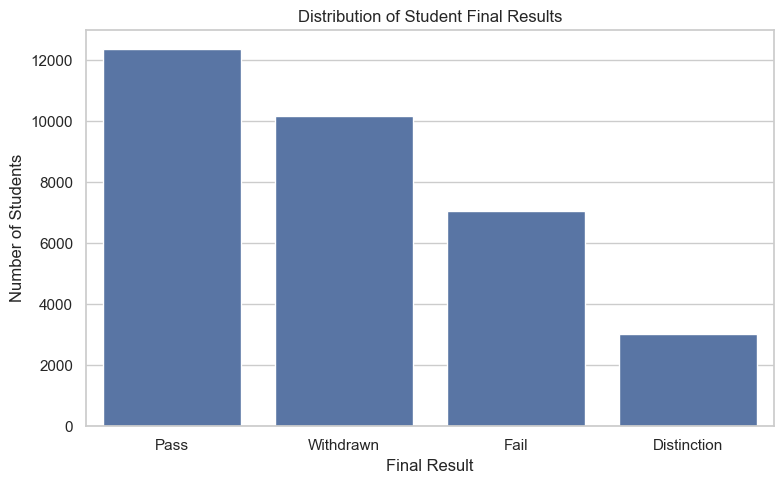

,Count,Percentage
final_result,,
Pass,12361,37.93
Withdrawn,10156,31.16
Fail,7052,21.64
Distinction,3024,9.28


In [74]:

# Visualize class distribution

plot_data = (
    student_info["final_result"]
    .fillna("Missing")
    .value_counts()
)

plt.figure(figsize=(8, 5))
sns.barplot(
    x=plot_data.index,
    y=plot_data.values
)

plt.title("Distribution of Student Final Results")
plt.xlabel("Final Result")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()


# Display class counts and percentages

class_distribution = (
    student_info["final_result"]
    .value_counts()
    .rename("Count")
    .to_frame()
)

class_distribution["Percentage"] = (
    student_info["final_result"]
    .value_counts(normalize=True) * 100
).round(2)

display(class_distribution)



#### Observations

The class distribution analysis shows that the four outcome categories are not equally represented in the OULAD dataset.

The `Pass` category contains the largest number of students, with 12,361 students (37.93%), followed by `Withdrawn` with 10,156 students (31.16%) and `Fail` with 7,052 students (21.64%). The `Distinction` category has the smallest number of students, with 3,024 students (9.28%).

The `Pass` category is approximately 4.1 times larger than the `Distinction` category. This difference indicates a potential class imbalance in the target variable `final_result`.

This imbalance should be considered when developing machine learning models. Accuracy alone may not fully represent model performance, so precision, recall, F1-score, and a confusion matrix should also be considered during evaluation.

### **5. Summary and Conclusion**

The OULAD dataset contains seven tables connected through student, course, and assessment identifiers.

The data quality analysis identified missing values in seven columns, fully duplicated records in studentVle, and potential outliers in several numerical variables. The final_result variable also shows an uneven class distribution, with Pass accounting for 37.93% and Distinction for 9.28% of students.